# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline as SklearnPipeline

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    roc_curve
)

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

from xgboost import XGBClassifier

import warnings
warnings.filterwarnings('ignore')

# ============================================================
# 2. LOAD DATASET
# ============================================================

In [9]:
df = pd.read_csv("Telco-Customer-Churn.csv")

print("Dataset Loaded Successfully!")

print("\nFirst 5 Rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
print(df.info())

print("\nStatistical Summary:")
print(df.describe())

Dataset Loaded Successfully!

First 5 Rows:
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport Stre

# ============================================================
# 3. DATA CLEANING
# ============================================================
# Remove duplicate records

In [10]:
df.drop_duplicates(inplace=True)

# Remove unnecessary spaces from column names
df.columns = df.columns.str.strip()

# Convert TotalCharges into numeric
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'],
    errors='coerce'
)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate values
print("\nDuplicate Rows:")
print(df.duplicated().sum())

# Remove customerID because it is a unique identifier
df.drop('customerID', axis=1, inplace=True)

# Convert target variable into numeric
df['Churn'] = df['Churn'].map({
    'No': 0,
    'Yes': 1
})

# Remove rows with missing target
df.dropna(subset=['Churn'], inplace=True)

df['Churn'] = df['Churn'].astype(int)

print("\nData Cleaning Completed!")


Missing Values:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Duplicate Rows:
0

Data Cleaning Completed!


# ============================================================
# 4. EXPLORATORY DATA ANALYSIS (EDA)
# ============================================================

# Churn Distribution

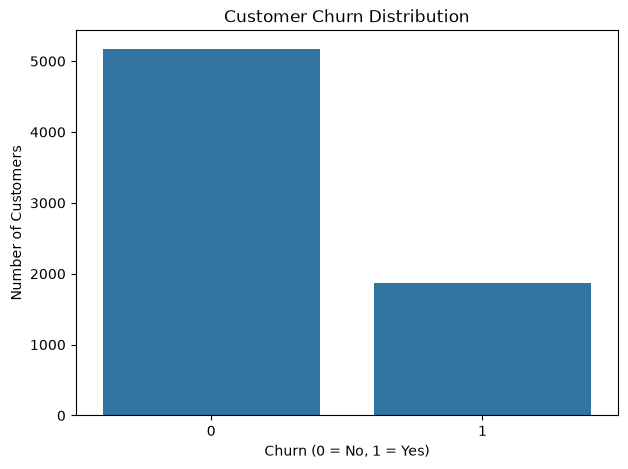

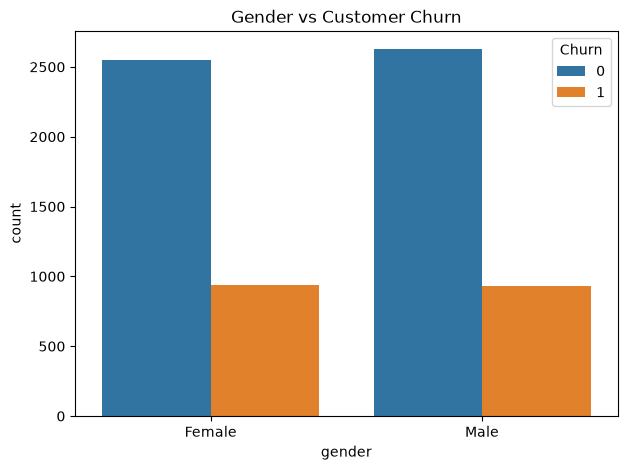

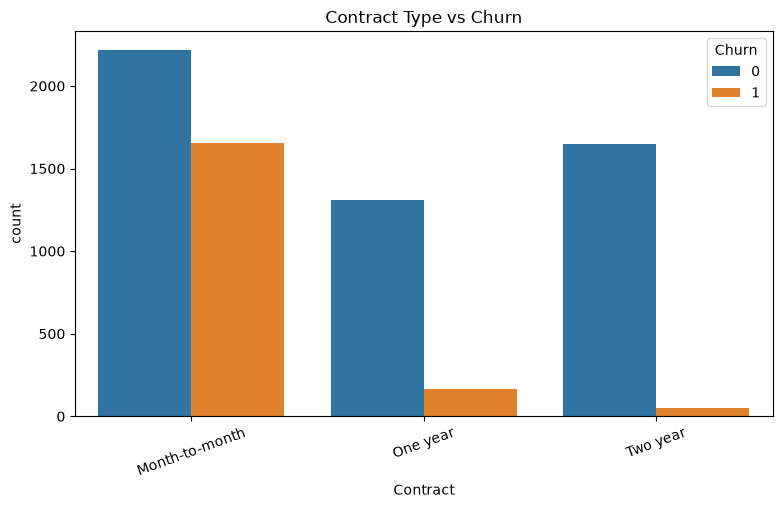

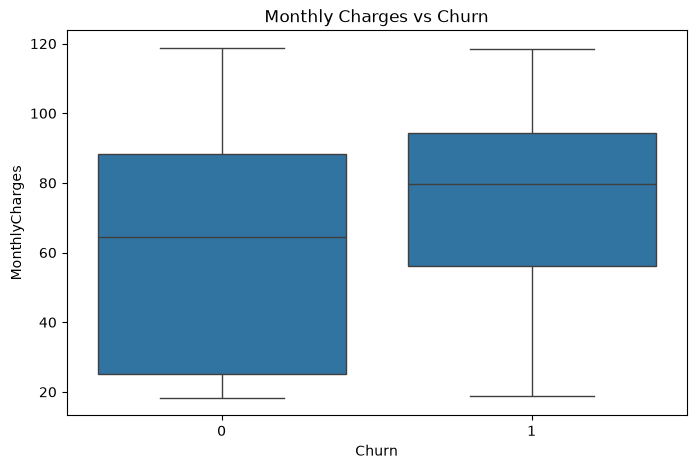

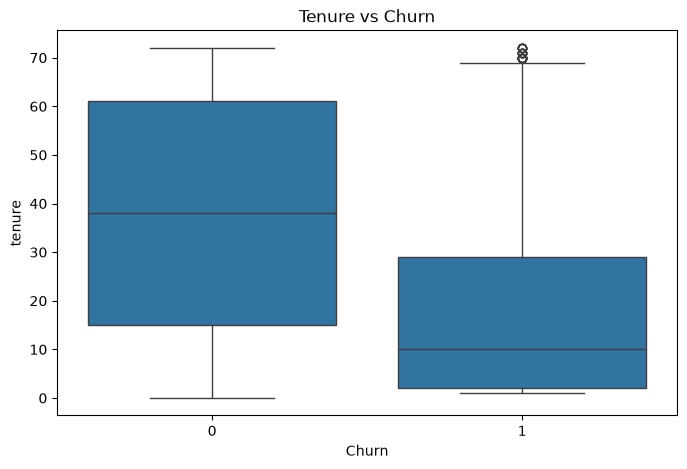

In [11]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Churn')

plt.title("Customer Churn Distribution")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")

plt.show()


# Gender vs Churn

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='gender', hue='Churn')

plt.title("Gender vs Customer Churn")

plt.show()


# Contract vs Churn

plt.figure(figsize=(9, 5))

sns.countplot(data=df, x='Contract', hue='Churn')

plt.title("Contract Type vs Churn")

plt.xticks(rotation=20)

plt.show()


# Monthly Charges vs Churn

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='Churn', y='MonthlyCharges')

plt.title("Monthly Charges vs Churn")

plt.show()


# Tenure vs Churn

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='Churn', y='tenure')

plt.title("Tenure vs Churn")

plt.show()


# ============================================================
# 5. SEPARATE FEATURES AND TARGET
# ============================================================

In [12]:
X = df.drop('Churn', axis=1)

y = df['Churn']

print("\nFeatures Shape:", X.shape)

print("Target Shape:", y.shape)



Features Shape: (7043, 19)
Target Shape: (7043,)


# ============================================================
# 6. IDENTIFY NUMERICAL AND CATEGORICAL COLUMNS
# ============================================================

In [13]:
numeric_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object']
).columns.tolist()

print("\nNumerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)


Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


# ============================================================
# 7. TRAIN TEST SPLIT
# ============================================================

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining Data:", X_train.shape)

print("Testing Data:", X_test.shape)


Training Data: (5634, 19)
Testing Data: (1409, 19)


# ============================================================
# 8. DATA PREPROCESSING
# ============================================================

In [15]:
# Numerical preprocessing

numeric_transformer = SklearnPipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median'))
    ]
)


# Categorical preprocessing

categorical_transformer = SklearnPipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(
            handle_unknown='ignore',
            sparse_output=False
        ))
    ]
)


# Combine preprocessing

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

# ============================================================
# 9. RANDOM FOREST CLASSIFIER
# ============================================================

In [16]:
rf_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),

        ('smote', SMOTE(random_state=42)),

        ('classifier', RandomForestClassifier(
            n_estimators=200,
            max_depth=None,
            random_state=42,
            n_jobs=-1
        ))
    ]
)


# Train Random Forest

rf_model.fit(X_train, y_train)

print("\nRandom Forest Training Completed!")


Random Forest Training Completed!



# ============================================================
# 10. XGBOOST CLASSIFIER
# ============================================================

In [17]:
xgb_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),

        ('smote', SMOTE(random_state=42)),

        ('classifier', XGBClassifier(
            n_estimators=200,
            learning_rate=0.05,
            max_depth=5,
            random_state=42,
            eval_metric='logloss',
            n_jobs=-1
        ))
    ]
)


# Train XGBoost

xgb_model.fit(X_train, y_train)

print("\nXGBoost Training Completed!")


XGBoost Training Completed!


# ============================================================
# 11. MODEL PREDICTIONS
# ============================================================

In [18]:

rf_predictions = rf_model.predict(X_test)

xgb_predictions = xgb_model.predict(X_test)


# Prediction Probabilities

rf_probabilities = rf_model.predict_proba(X_test)[:, 1]

xgb_probabilities = xgb_model.predict_proba(X_test)[:, 1]

# ============================================================
# 12. MODEL EVALUATION
# ============================================================

In [19]:
def evaluate_model(name, y_true, predictions, probabilities):

    print("\n===================================")
    print(name)
    print("===================================")

    accuracy = accuracy_score(y_true, predictions)

    precision = precision_score(y_true, predictions)

    recall = recall_score(y_true, predictions)

    f1 = f1_score(y_true, predictions)

    roc_auc = roc_auc_score(y_true, probabilities)

    print("Accuracy:", round(accuracy, 4))

    print("Precision:", round(precision, 4))

    print("Recall:", round(recall, 4))

    print("F1 Score:", round(f1, 4))

    print("ROC-AUC Score:", round(roc_auc, 4))

    print("\nClassification Report:")

    print(classification_report(y_true, predictions))

    return roc_auc


rf_auc = evaluate_model(
    "RANDOM FOREST",
    y_test,
    rf_predictions,
    rf_probabilities
)


xgb_auc = evaluate_model(
    "XGBOOST",
    y_test,
    xgb_predictions,
    xgb_probabilities
)


RANDOM FOREST
Accuracy: 0.7771
Precision: 0.5962
Recall: 0.4973
F1 Score: 0.5423
ROC-AUC Score: 0.8194

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.88      0.85      1035
           1       0.60      0.50      0.54       374

    accuracy                           0.78      1409
   macro avg       0.71      0.69      0.70      1409
weighted avg       0.77      0.78      0.77      1409


XGBOOST
Accuracy: 0.7977
Precision: 0.629
Recall: 0.5802
F1 Score: 0.6036
ROC-AUC Score: 0.8414

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.88      0.86      1035
           1       0.63      0.58      0.60       374

    accuracy                           0.80      1409
   macro avg       0.74      0.73      0.73      1409
weighted avg       0.79      0.80      0.80      1409




# ============================================================
# 13. MODEL COMPARISON
# ============================================================

In [20]:
comparison = pd.DataFrame({

    'Model': ['Random Forest', 'XGBoost'],

    'Accuracy': [
        accuracy_score(y_test, rf_predictions),
        accuracy_score(y_test, xgb_predictions)
    ],

    'Precision': [
        precision_score(y_test, rf_predictions),
        precision_score(y_test, xgb_predictions)
    ],

    'Recall': [
        recall_score(y_test, rf_predictions),
        recall_score(y_test, xgb_predictions)
    ],

    'F1 Score': [
        f1_score(y_test, rf_predictions),
        f1_score(y_test, xgb_predictions)
    ],

    'ROC-AUC': [
        rf_auc,
        xgb_auc
    ]

})

print("\nMODEL COMPARISON")

print(comparison)


MODEL COMPARISON
           Model  Accuracy  Precision    Recall  F1 Score   ROC-AUC
0  Random Forest  0.777147   0.596154  0.497326  0.542274  0.819439
1        XGBoost  0.797729   0.628986  0.580214  0.603616  0.841413


# ============================================================
# 14. CROSS VALIDATION
# ============================================================

In [21]:
rf_cv = cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)

xgb_cv = cross_val_score(
    xgb_model,
    X_train,
    y_train,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)

print("\nRandom Forest Cross Validation:")
print(rf_cv)

print("Random Forest Mean ROC-AUC:", rf_cv.mean())


print("\nXGBoost Cross Validation:")
print(xgb_cv)

print("XGBoost Mean ROC-AUC:", xgb_cv.mean())




Random Forest Cross Validation:
[0.83816223 0.82909618 0.81967064 0.80884551 0.80266143]
Random Forest Mean ROC-AUC: 0.8196871986879255

XGBoost Cross Validation:
[0.85773835 0.84915297 0.84484514 0.83028775 0.82562997]
XGBoost Mean ROC-AUC: 0.8415308381897371


# ============================================================
# 15. ROC-AUC CURVE
# ============================================================


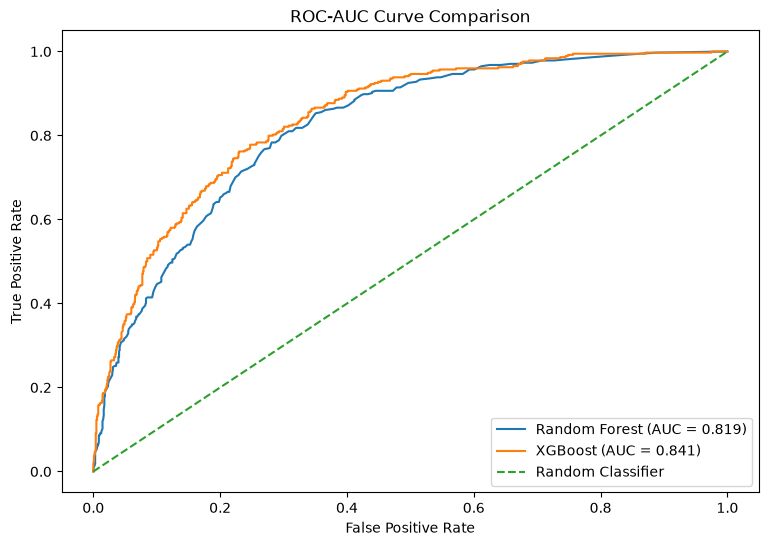

In [22]:
rf_fpr, rf_tpr, _ = roc_curve(
    y_test,
    rf_probabilities
)

xgb_fpr, xgb_tpr, _ = roc_curve(
    y_test,
    xgb_probabilities
)


plt.figure(figsize=(9, 6))

plt.plot(
    rf_fpr,
    rf_tpr,
    label=f'Random Forest (AUC = {rf_auc:.3f})'
)

plt.plot(
    xgb_fpr,
    xgb_tpr,
    label=f'XGBoost (AUC = {xgb_auc:.3f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC-AUC Curve Comparison")

plt.legend()

plt.show()

# ============================================================
# 16. CONFUSION MATRIX
# ============================================================

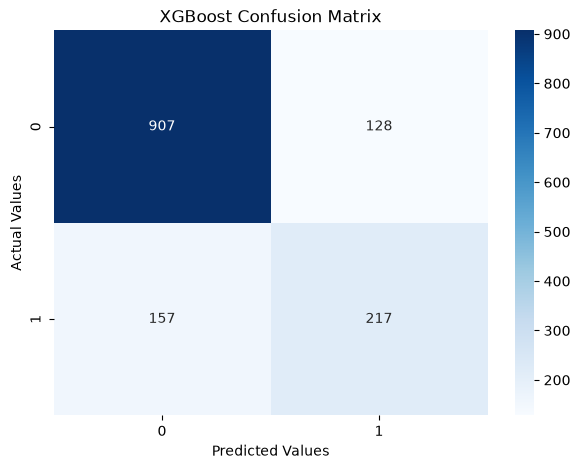

In [23]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    confusion_matrix(y_test, xgb_predictions),
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("XGBoost Confusion Matrix")

plt.xlabel("Predicted Values")

plt.ylabel("Actual Values")

plt.show()

# ============================================================
# 17. FEATURE IMPORTANCE - RANDOM FOREST
# ============================================================


RANDOM FOREST TOP 10 FEATURES
                                Feature  Importance
3                     num__TotalCharges    0.101112
1                           num__tenure    0.084797
36         cat__Contract_Month-to-month    0.082054
2                   num__MonthlyCharges    0.079762
18               cat__OnlineSecurity_No    0.064434
43  cat__PaymentMethod_Electronic check    0.060589
27                  cat__TechSupport_No    0.052092
21                 cat__OnlineBackup_No    0.033348
38               cat__Contract_Two year    0.030801
16     cat__InternetService_Fiber optic    0.027321


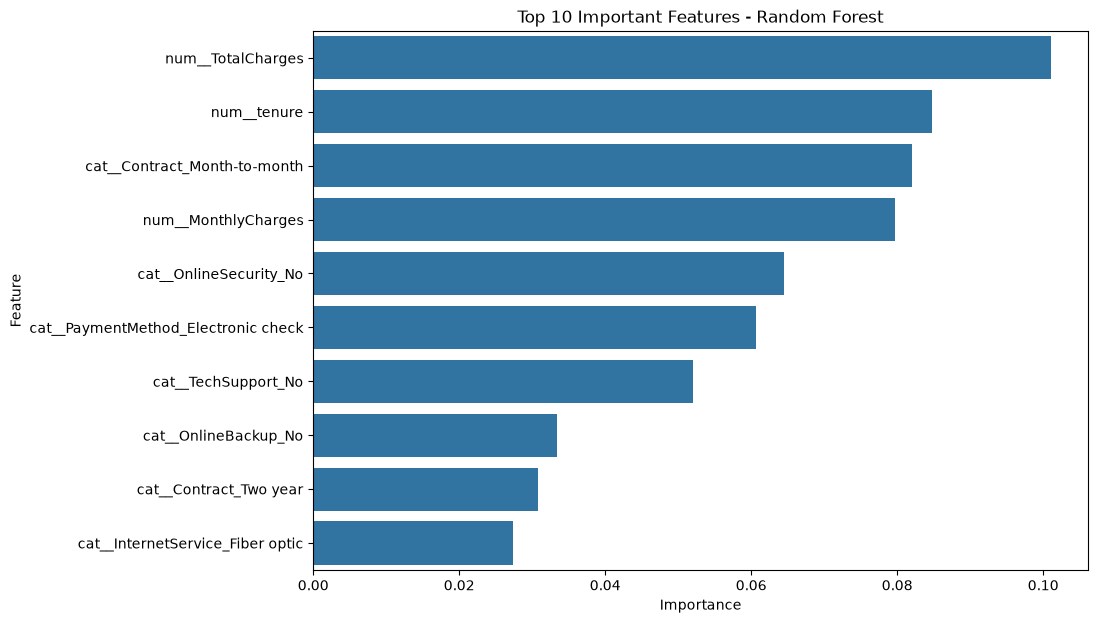

In [24]:
rf_preprocessor = rf_model.named_steps['preprocessor']

rf_classifier = rf_model.named_steps['classifier']

feature_names = rf_preprocessor.get_feature_names_out()

rf_importance = pd.DataFrame({

    'Feature': feature_names,

    'Importance': rf_classifier.feature_importances_

})

rf_importance = rf_importance.sort_values(
    by='Importance',
    ascending=False
)

print("\nRANDOM FOREST TOP 10 FEATURES")

print(rf_importance.head(10))


plt.figure(figsize=(10, 7))

sns.barplot(
    data=rf_importance.head(10),
    x='Importance',
    y='Feature'
)

plt.title("Top 10 Important Features - Random Forest")

plt.show()

# ============================================================
# 18. FEATURE IMPORTANCE - XGBOOST
# ============================================================


XGBOOST TOP 10 FEATURES
                                Feature  Importance
36         cat__Contract_Month-to-month    0.433075
18               cat__OnlineSecurity_No    0.075330
27                  cat__TechSupport_No    0.067473
43  cat__PaymentMethod_Electronic check    0.054095
16     cat__InternetService_Fiber optic    0.038451
21                 cat__OnlineBackup_No    0.028423
39             cat__PaperlessBilling_No    0.023419
30                  cat__StreamingTV_No    0.022429
15             cat__InternetService_DSL    0.021059
32                 cat__StreamingTV_Yes    0.018388


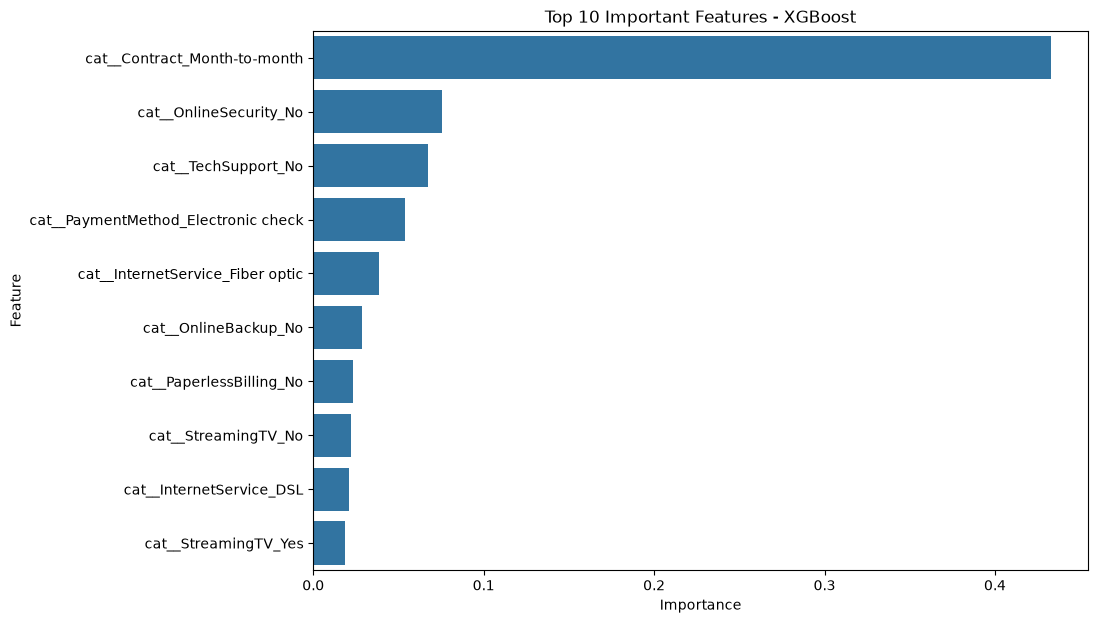

In [25]:
xgb_preprocessor = xgb_model.named_steps['preprocessor']

xgb_classifier = xgb_model.named_steps['classifier']

xgb_feature_names = xgb_preprocessor.get_feature_names_out()

xgb_importance = pd.DataFrame({

    'Feature': xgb_feature_names,

    'Importance': xgb_classifier.feature_importances_

})

xgb_importance = xgb_importance.sort_values(
    by='Importance',
    ascending=False
)

print("\nXGBOOST TOP 10 FEATURES")

print(xgb_importance.head(10))


plt.figure(figsize=(10, 7))

sns.barplot(
    data=xgb_importance.head(10),
    x='Importance',
    y='Feature'
)

plt.title("Top 10 Important Features - XGBoost")

plt.show()

# ============================================================
# 19. FINAL RESULT
# ============================================================

In [26]:
print("\n===================================")

print("PROJECT COMPLETED SUCCESSFULLY!")

print("===================================")

print("Random Forest ROC-AUC:", round(rf_auc, 4))

print("XGBoost ROC-AUC:", round(xgb_auc, 4))

print("\nBest Model:")

if rf_auc > xgb_auc:

    print("Random Forest")

else:

    print("XGBoost")

print("\nTarget ROC-AUC: Greater than 0.80")

print("===================================")


PROJECT COMPLETED SUCCESSFULLY!
Random Forest ROC-AUC: 0.8194
XGBoost ROC-AUC: 0.8414

Best Model:
XGBoost

Target ROC-AUC: Greater than 0.80
